# Predicting Multi-Planet Exoplanet Host Stars

**SI 670 Applied Machine Learning · Fall 2026 ·  Team Alien**

**Question** Using only a star's observable properties, can we predict whether it hosts one known planet or multiple known planets? 

**Notebook Map** 

1. Setup
2. Load the raw data
3. Data Manipulatio: collapse to one row per star and build the target
4. Exploratory data analysis 
5. Preprocessing feature selection: missing values, train/test split, scaling
6. Models: baseline + Logistic Regression, k-Nearest Neighbors, Decision Tree, Random Forest
7. Evaluation on the held-out test set
8. Interpretation
9. Experiment 2: does adding observational context help? 
10. Precision vs. recall trade-off

Every figure is saved to `figures/` at 300 dpi so it can be dropped straight into the poster.

# The Main Columns that will be used throughout this project: 

| Column | Meaning | Units |
|---|---|---|
| `st_teff` | Stellar effective (surface) temperature | Kelvin |
| `st_rad` | Stellar radius | Solar radii |
| `st_mass` | Stellar mass | Solar masses |
| `st_met` | Metallicity: abundance of elements heavier than helium vs. the Sun (log scale; 0 = Sun) | dex |
| `st_logg` | Surface gravity (log10) | log10(cm/s²) |
| `sy_snum` | Number of stars in the system | count |
| `sy_dist` | Distance from Earth | parsecs |
| `sy_kmag` | Brightness in the infrared K band (lower = brighter) | magnitude |
| `first_disc_method` | How the first planet was found | category |

# 1. Setup

**Special Note:** AI was used for the setup in order to ensure all the correct models were imported and a consistent setup was created for easier model and figure creation down in later code. 

In [2]:
from pathlib import Path
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

from sklearn.metrics import(
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
)

# Data Path
data_path = Path("data/PSCompPars_2026.11.14_13.55.11.csv")
fig_dir = Path("figures")
results_dir = Path("results")
fig_dir.mkdir(exist_ok=True)
results_dir.mkdir(exist_ok=True)

random_state = 42 # Random state for reproducibility

# One Consistent look for every figure
single_color = "#2a78d6" # blue = stars with 1 known planet
multi_color = "#eb6834" # organ = stars with 2+ known planets
model_colors = {
    "Logistic Regression": "#2a78d6",
    "k-Nearest Neighbors": "#eb6834",
    "Decision Tree": "#1baf7a",
    "Random Forest": "#eda100",
} #fixed color for each model to keep consistency across figures
baseline_color = "#8a8985"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

def save_fig(fig, name):
    """Save a figure for the poster/report and show it in the notebook."""
    fig.savefig(fig_dir / f"{name}.png")
    plt.show()

# 2. Load the raw data

The NASA Exoplanet Archive Planetary Systems Composite Parameters (PSCompPars) table. The CSV starts with ~88 lines of # comments describing each column, so we skip them with `comment = '#'`. 

**Imporant:** this table has one row per planet, not one row per star. 

In [3]:
raw = pd.read_csv(data_path, comment="#")

print(f"Raw table {raw.shape[0]:,} planets x {raw.shape[1]} columns")
print(f"Unique host stars {raw['hostname'].nunique():,} stars")
print(raw.columns)
raw[["pl_name", "hostname", "sy_pnum", "discoverymethod", "st_teff", "st_mass", "st_met"]].head(5)

Raw table 6,470 planets x 84 columns
Unique host stars 4,862 stars
Index(['pl_name', 'hostname', 'sy_snum', 'sy_pnum', 'discoverymethod',
       'disc_year', 'disc_facility', 'pl_controv_flag', 'pl_orbper',
       'pl_orbpererr1', 'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax',
       'pl_orbsmaxerr1', 'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade',
       'pl_radeerr1', 'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1',
       'pl_radjerr2', 'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1',
       'pl_bmasseerr2', 'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1',
       'pl_bmassjerr2', 'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen',
       'pl_orbeccenerr1', 'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol',
       'pl_insolerr1', 'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1',
       'pl_eqterr2', 'pl_eqtlim', 'ttv_flag', 'st_spectype', 'st_teff',
       'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1',
       'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_mas

,pl_name,hostname,sy_pnum,discoverymethod,st_teff,st_mass,st_met
0,11 Com b,11 Com,1,Radial Velocity,4874.0,2.09,-0.26
1,11 UMi b,11 UMi,1,Radial Velocity,4213.0,2.78,-0.02
2,14 And b,14 And,1,Radial Velocity,4888.0,1.78,-0.21
3,14 Her b,14 Her,2,Radial Velocity,5338.0,0.97,0.43
4,16 Cyg B b,16 Cyg B,1,Radial Velocity,5750.0,1.08,0.06


# 3. Data manipulation: one row per star

Our question is about **stars**, so we collapse the planet table to one row per hostname. This matters for two resons: 

1. **Correct unit of analysis:** A star with 5 planets would otherwise appear 5 times and. be weighted 5x. 

2. **Avoiding leakage:** If the same star appeared in both the train and test sets, the model could "memorize" the star and look better than it really is. 

How each column is collapsed: 
- **Stellar properties (temperature, radius, mass, metallicity, surface gravity):** the median across that star's rows. The composite table occasionally lists slightly different values for the same star (~200 stars), and the median helps to smooth that out. 

- **System properties (sy_pnum, sy_snum, distance, brightness):** identical across rows, so we take the first value. 

- **Discovery method:** the method used for the star's first discovered planet. 

**Target**: `is_multi = 1` if `sy_pnum >= 2`, else `0`


In [4]:
stellar_cols = ["st_teff", "st_rad","st_mass","st_met","st_logg"]
system_cols = ["sy_pnum", "sy_snum", "sy_dist", "sy_kmag"]

#Discover method of each star's earliest-discovered planet
first_method = (
    raw.sort_values("disc_year")
    .groupby("hostname")["discoverymethod"]
    .first()
    .rename("first_discoverymethod")
)

stars = (
    raw.groupby("hostname")
    .agg({**{c: "median" for c in stellar_cols}, **{c: "first" for c in system_cols}})
    .join(first_method)
)

# Binary target: 1 if star has multiple planets, 0 if star has only one planet

stars["is_multi"] = (stars["sy_pnum"] >= 2).astype(int)

print(f"Star-level table: {stars.shape[0]:,} stars")

stars.head()


Star-level table: 4,862 stars


,st_teff,st_rad,st_mass,st_met,st_logg,sy_pnum,sy_snum,sy_dist,sy_kmag,first_discoverymethod,is_multi
hostname,,,,,,,,,,,
11 Com,4874.0,13.76,2.09,-0.26,2.45,1,2,93.1846,2.282,Radial Velocity,0
11 UMi,4213.0,29.79,2.78,-0.02,1.93,1,1,125.3210,1.939,Radial Velocity,0
14 And,4888.0,11.55,1.78,-0.21,2.55,1,1,75.4392,2.331,Radial Velocity,0
14 Her,5338.0,0.93,0.97,0.43,4.45,2,1,17.9323,4.714,Radial Velocity,1
16 Cyg B,5750.0,1.13,1.08,0.06,4.36,1,3,21.1397,4.651,Radial Velocity,0


# 4. Exploratory data analysis

### 4.1 Class Balance

About 1 in 5 stars hosts multiple known planets, so the classes are **imbalanced**. A model that always says "single planet" would already be ~78% accurate, which is why accuracy alone is a misleading metric here.

sy_pnum
1    3779
2     727
3     226
4      84
5      30
6      12
7       3
8       1

Stars with multi-planet hosts: 22.27%


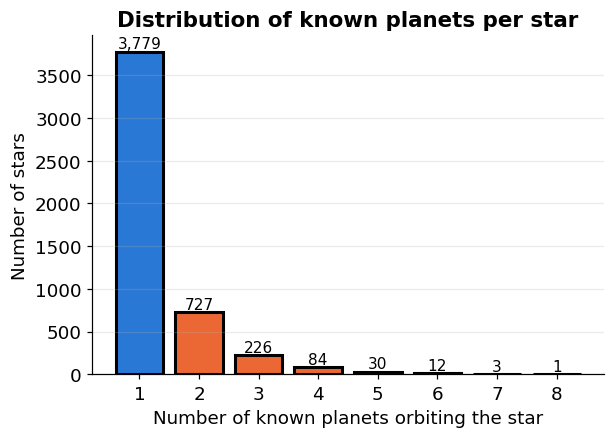

In [5]:
counts = stars["sy_pnum"].value_counts().sort_index()
print(counts.to_string())
print(f"\nStars with multi-planet hosts: {stars['is_multi'].mean():.2%}")

fig, ax = plt.subplots(figsize=(6,4))
bar_colors = [single_color if p == 1 else multi_color for p in counts.index]
ax.bar(counts.index.astype(str), counts.values, color=bar_colors, edgecolor="black", linewidth = 2)
for x, y in zip(counts.index.astype(str), counts.values):
    ax.text(x, y + 35, f"{y:,}", ha="center", fontsize=10)
ax.set_xlabel("Number of known planets orbiting the star")
ax.set_ylabel("Number of stars")
ax.set_title("Distribution of known planets per star")
ax.grid(axis="x", visible = False)
save_fig(fig, "fig1_class_balance")

### 4.2 Mising Values

In our proposal, we mentioned dropping rows with missing stellar values if that removes < 20% of the data, otherwise we would impute. Now we need to check that below

In [17]:
missing = stars[stellar_cols + ["sy_snum", "sy_dist", "sy_kmag", "first_discoverymethod"]].isna().mean()
print(f"Share missing per column:\n {(missing * 100).round(2).astype(str) + '%'}")

share_dropped = stars[stellar_cols].isna().any(axis=1).mean()
print(f"\nStars missing at least one stellar feature: {share_dropped:.2%} ->"
      f"{"DROP them (under 20%)" if share_dropped <0.2 else "IMPUTE (over 20%)"}")


Share missing per column:
 st_teff                   6.11%
st_rad                    6.48%
st_mass                   0.16%
st_met                   13.16%
st_logg                   6.62%
sy_snum                    0.0%
sy_dist                   0.58%
sy_kmag                   5.94%
first_discoverymethod      0.0%
dtype: object

Stars missing at least one stellar feature: 13.37% ->DROP them (under 20%)


**Special note:** Spectral type (`st_spectype`) is ~65% missing, which is why we did not keep it. Temperature carries most of the same information anyway (spectral type is essentially a temperature class). 

In [6]:
has_missing = stars[stellar_cols].isna().any(axis=1)

print(f"Multi-planet share among stars WITH missing values: {stars.loc[has_missing, 'is_multi'].mean():.2%}")
print(f"Multi-planet share among stars WITHOUT missing values: {stars.loc[~has_missing, 'is_multi'].mean():.2%}")

Multi-planet share among stars WITH missing values: 8.15%
Multi-planet share among stars WITHOUT missing values: 24.45%


### 4.3 Skewed Features

Radius, mass, and distance span several orders of magnitude (e.g. star radius from 0.01 to 88 solar radii). We decided to take log10 of these so a handful of giant stars don't dominate scale-sensitive models like Logistic Regression and k-NN. 

In [23]:
for col in ["st_rad","st_mass", "sy_dist"]:
    stars[f"log_{col}"] = np.log10(stars[col])

stars[["st_rad", "log_st_rad", "st_mass", "log_st_mass", "sy_dist", "log_sy_dist"]].describe().round(2)

,st_rad,log_st_rad,st_mass,log_st_mass,sy_dist,log_sy_dist
count,4547.00,4547.00,4854.00,4854.00,4834.00,4834.00
mean,1.60,0.02,0.95,-0.07,786.96,2.49
std,4.17,0.30,0.41,0.23,1370.98,0.64
min,0.01,-1.94,0.01,-2.03,1.30,0.11
25%,0.78,-0.11,0.77,-0.11,114.08,2.06
50%,0.97,-0.01,0.95,-0.02,373.87,2.57
75%,1.28,0.11,1.10,0.04,843.97,2.93
max,88.48,1.95,9.10,0.96,8500.00,3.93


### 4.4 Do single- and multi-planet hosts look different? 

Overlaid, density normalized histograms of each stellar feature by class. If the two shapes overlap almost completely, that feature along wont seperate the classes well. 